In [106]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, roc_curve, classification_report
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from imblearn.over_sampling import SMOTE

In [107]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [108]:
!pip install pyreadstat
df = pd.read_spss("/content/drive/MyDrive/Python_datasets/Nig_Women_MICs_data.sav", convert_categoricals=False)

In [129]:
#Data preprocessing

# Replace standard missing codes
df.replace([9, 99, 999, 96], np.nan, inplace=True)

# Replace values 90–99 as missing
for col in df.columns:
    df[col] = df[col].apply(
        lambda x: np.nan if (isinstance(x, (int, float)) and 90 <= x <= 99) else x
    )

# Keep only women with at least 1 child
df = df[df["CEB"] >= 1]



# 4. TARGET VARIABLE
df["child_death"] = np.where(
    (df["CEB"] - df["CSURV"]) > 0, 1, 0
)

### Descriptive Statistics on Cleaned Data

Now that the initial data preprocessing has been applied to `df`, we can calculate descriptive statistics like child mortality counts and prevalence on this cleaned and filtered dataset. This ensures consistency with the data used for subsequent modeling.

In [130]:
# Create df_desc from the fully preprocessed df
# The 'df' has already been filtered for 'CEB >= 1' in the previous step (Z_2gXNjDik27)
df_desc_cleaned = df.copy()

print(f"Rows in df after filtering: {len(df)}")
print(f"Rows in df_desc_cleaned after copy: {len(df_desc_cleaned)}")

# Assuming child mortality = 1 if any child died (using the cleaned df)
df_desc_cleaned["child_mortality"] = np.where(df_desc_cleaned["CEB"] > df_desc_cleaned["CSURV"], 1, 0)

# ---- COUNT ----
death_counts_cleaned = df_desc_cleaned["child_mortality"].value_counts()

# ---- PREVALENCE ----
death_prevalence_cleaned = df_desc_cleaned["child_mortality"].mean()

Rows in df after filtering: 9612
Rows in df_desc_cleaned after copy: 9612


In [131]:
df_desc_cleaned["child_deaths"] = df_desc_cleaned["CEB"] - df_desc_cleaned["CSURV"]

# Group into categories: 0,1,2,3,4, ≥5
def categorize_deaths(x):
    if pd.isna(x):  # Handle NaN values
        return np.nan
    if x >= 5:
        return "5+"
    else:
        return str(int(x))

df_desc_cleaned["death_category"] = df_desc_cleaned["child_deaths"].apply(categorize_deaths)

# Count per category (ensure correct order)
order = ["0", "1", "2", "3", "4", "5+"]
death_dist_cleaned = df_desc_cleaned["death_category"].value_counts().reindex(order, fill_value=0)

death_prevalence_pct_cleaned = df_desc_cleaned["child_mortality"].mean() * 100

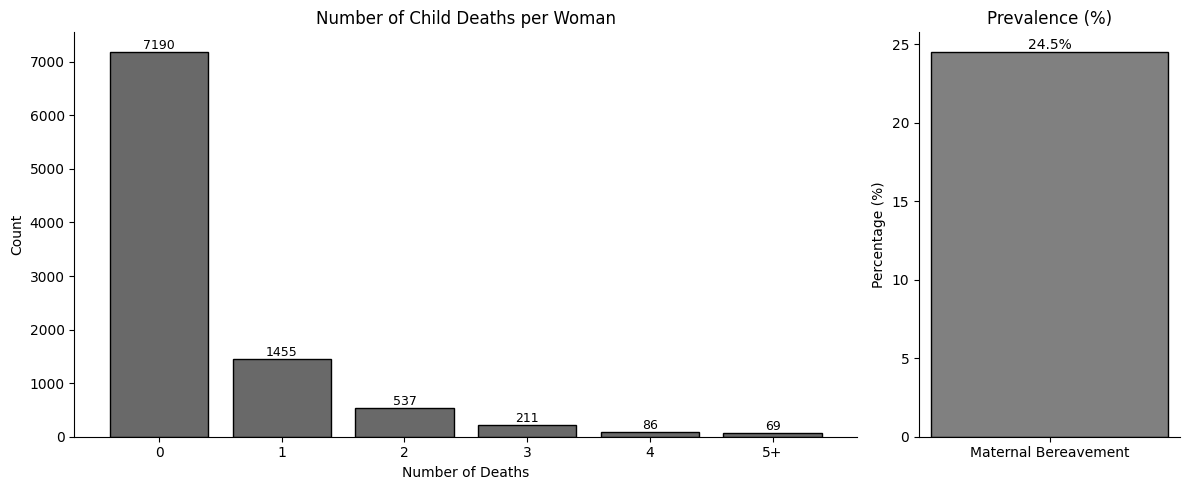

In [132]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    gridspec_kw={'width_ratios': [3, 1]}  # Wider count plot, narrower prevalence
)

# ---- LEFT: DISTRIBUTION OF CHILD DEATHS (CLEANED DATA) ----
bars = axes[0].bar(
    death_dist_cleaned.index,
    death_dist_cleaned.values,
    color='dimgray',
    edgecolor='black'
)

axes[0].set_title("Number of Child Deaths per Woman")
axes[0].set_xlabel("Number of Deaths")
axes[0].set_ylabel("Count")

# Add counts on top of bars
for bar in bars:
    height = bar.get_height()
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height)}",
        ha='center',
        va='bottom',
        fontsize=9
    )

# ---- RIGHT: PREVALENCE (CLEANED DATA) ----
bars2 = axes[1].bar(
    ["Maternal Bereavement"],
    [death_prevalence_pct_cleaned],
    color='gray',
    edgecolor='black',
    width=0.4  # Make bar slimmer
)

axes[1].set_title("Prevalence (%)")
axes[1].set_ylabel("Percentage (%)")

# Add percentage label
for bar in bars2:
    height = bar.get_height()
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.1f}%",
        ha='center',
        va='bottom',
        fontsize=10
    )

# Clean up look
for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

In [133]:
#Feature Engineering
#ANC meeting

# Keep MN2 as is (do NOT force missing to No)
df["MN2"] = df["MN2"].replace([9, 99], np.nan)

# Clean related variables
df["MN5"] = df["MN5"].replace([9, 99], np.nan)
df["MN4AU_1"] = df["MN4AU_1"].replace([9, 99], np.nan)
df["MN4AN_2"] = df["MN4AN_2"].replace([9, 99], np.nan)

# Skilled ANC
df["skilled_anc"] = np.where(
    (df["MN3A"].notna()) | (df["MN3B"].notna()),
    1, 0
)

# If NO ANC → force zeros
df.loc[df["MN2"] == 2, "MN5"] = 0
df.loc[df["MN2"] == 2, "MN4AN_2"] = 0
df.loc[df["MN2"] == 2, "skilled_anc"] = 0

# ANC timing (convert to months)
df["anc_months"] = np.where(
    df["MN4AU_1"] == 1,
    df["MN4AN_2"] / 4,
    df["MN4AN_2"]
)

df["anc_months"] = df["anc_months"].fillna(0)

In [134]:
#Place of Delivery
df = df[df["MN20"].notna()]

df["place_delivery"] = np.select(
    [
        df["MN20"].isin([21, 22, 23, 31, 32]),
        df["MN20"].isin([33, 36, 26]),
        df["MN20"].isin([11, 12])
    ],
    [1, 2, 3],
    default=np.nan
)


In [135]:
#polygamy
df["MA3"] = df["MA3"].replace([9, 99], np.nan)

In [136]:
#Features
df_model = df[[
    "child_death",
    "CEB",
    "WB4",
    "welevel",
    "MA1",
    "MA3",
    "MA11C",
    "wscore",
    "HH6",
    "zone",
    "MN2",
    "MN5",
    "anc_months",
    "skilled_anc",
    "place_delivery"
]].copy()

df_model = df_model.dropna()

In [137]:
#Encode categorical variables

categorical_cols = ["welevel", "MA1", "HH6", "zone", "place_delivery"]

df_model = pd.get_dummies(df_model, columns=categorical_cols, drop_first=True)

In [139]:
#Train_test split

X = df_model.drop("child_death", axis=1)
y = df_model["child_death"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [140]:
from sklearn.preprocessing import StandardScaler

#Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [141]:
#Apply SMOTE
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

In [142]:
#Logistic regression
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_smote, y_train_smote)
y_pred_lr = lr.predict(X_test_scaled)
y_prob_lr = lr.predict_proba(X_test_scaled)[:, 1]

print("\n--- Logistic Regression (SMOTE) ---")
print("ROC-AUC:", roc_auc_score(y_test, y_prob_lr))
print(classification_report(y_test, y_pred_lr))


--- Logistic Regression (SMOTE) ---
ROC-AUC: 0.79065442044659
              precision    recall  f1-score   support

           0       0.88      0.74      0.80      1311
           1       0.47      0.70      0.57       438

    accuracy                           0.73      1749
   macro avg       0.68      0.72      0.69      1749
weighted avg       0.78      0.73      0.74      1749



In [143]:
#Random forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_smote, y_train_smote)
y_pred_rf = rf.predict(X_test_scaled)
y_prob_rf = rf.predict_proba(X_test_scaled)[:, 1]

print("\n--- Random Forest (SMOTE) ---")
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))
print(classification_report(y_test, y_pred_rf))


--- Random Forest (SMOTE) ---
ROC-AUC: 0.7585263784834332
              precision    recall  f1-score   support

           0       0.82      0.88      0.85      1311
           1       0.54      0.44      0.48       438

    accuracy                           0.77      1749
   macro avg       0.68      0.66      0.67      1749
weighted avg       0.75      0.77      0.76      1749



In [144]:
#Gradient_Boost
gb = GradientBoostingClassifier(random_state=42)
gb.fit(X_train_smote, y_train_smote)
y_pred_gb = gb.predict(X_test_scaled)
y_prob_gb = gb.predict_proba(X_test_scaled)[:, 1]

print("\n--- Gradient Boosting (SMOTE) ---")
print("ROC-AUC:", roc_auc_score(y_test, y_prob_gb))
print(classification_report(y_test, y_pred_gb))


--- Gradient Boosting (SMOTE) ---
ROC-AUC: 0.7895146094340476
              precision    recall  f1-score   support

           0       0.84      0.86      0.85      1311
           1       0.54      0.49      0.52       438

    accuracy                           0.77      1749
   macro avg       0.69      0.68      0.68      1749
weighted avg       0.76      0.77      0.76      1749



In [145]:
#Model evaluation
def evaluate_model(name, y_test, y_pred, y_prob):
    print(f"\n--- {name} ---")
    print("ROC-AUC:", roc_auc_score(y_test, y_prob))
    print(classification_report(y_test, y_pred))

evaluate_model("Logistic Regression (SMOTE)", y_test, y_pred_lr, y_prob_lr)
evaluate_model("Random Forest (SMOTE)", y_test, y_pred_rf, y_prob_rf)
evaluate_model("Gradient Boosting (SMOTE)", y_test, y_pred_gb, y_prob_gb)


--- Logistic Regression (SMOTE) ---
ROC-AUC: 0.79065442044659
              precision    recall  f1-score   support

           0       0.88      0.74      0.80      1311
           1       0.47      0.70      0.57       438

    accuracy                           0.73      1749
   macro avg       0.68      0.72      0.69      1749
weighted avg       0.78      0.73      0.74      1749


--- Random Forest (SMOTE) ---
ROC-AUC: 0.7585263784834332
              precision    recall  f1-score   support

           0       0.82      0.88      0.85      1311
           1       0.54      0.44      0.48       438

    accuracy                           0.77      1749
   macro avg       0.68      0.66      0.67      1749
weighted avg       0.75      0.77      0.76      1749


--- Gradient Boosting (SMOTE) ---
ROC-AUC: 0.7895146094340476
              precision    recall  f1-score   support

           0       0.84      0.86      0.85      1311
           1       0.54      0.49      0.52       43

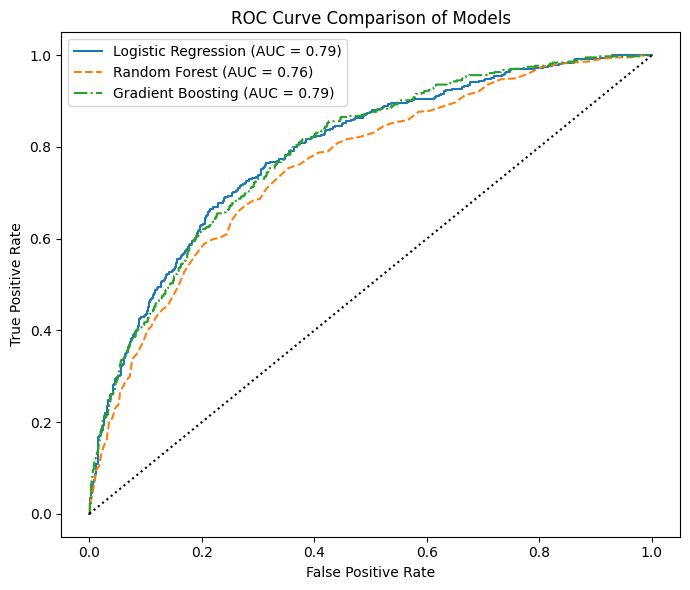

In [146]:
# ===============================
# 16. ROC CURVE PLOT (ALL MODELS)
# ===============================
from sklearn.metrics import roc_curve

plt.figure(figsize=(7, 6))

# Logistic Regression
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
plt.plot(fpr_lr, tpr_lr, linestyle='-', label=f'Logistic Regression (AUC = {roc_auc_score(y_test, y_prob_lr):.2f})')

# Random Forest
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
plt.plot(fpr_rf, tpr_rf, linestyle='--', label=f'Random Forest (AUC = {roc_auc_score(y_test, y_prob_rf):.2f})')

# Gradient Boosting
fpr_gb, tpr_gb, _ = roc_curve(y_test, y_prob_gb)
plt.plot(fpr_gb, tpr_gb, linestyle='-.', label=f'Gradient Boosting (AUC = {roc_auc_score(y_test, y_prob_gb):.2f})')

# Diagonal line (random classifier)
plt.plot([0, 1], [0, 1], color='black', linestyle=':')

# Labels
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison of Models")

plt.legend()
plt.grid(False)

plt.tight_layout()
plt.show()

In [147]:
#Feature importance
importances = pd.Series(rf.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=False)

print("\nTop Predictors:")
print(importances.head(10))


Top Predictors:
CEB                   0.248209
wscore                0.139685
WB4                   0.130958
MA11C                 0.130113
MN5                   0.072099
anc_months            0.067029
zone_3.0              0.032481
place_delivery_3.0    0.026364
MA3                   0.023686
HH6_2.0               0.021745
dtype: float64


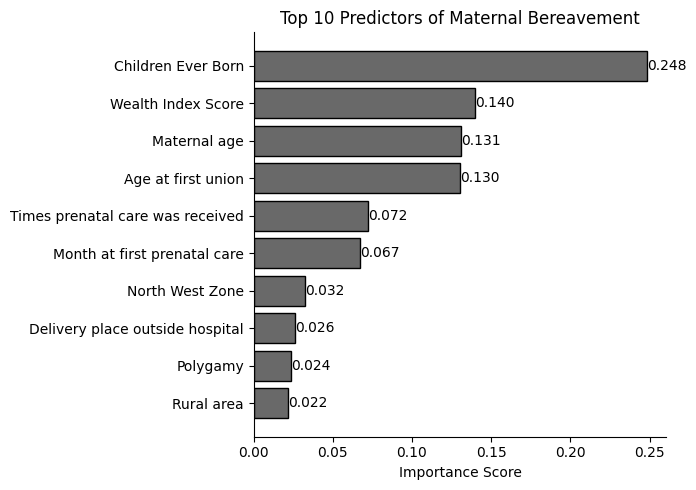

In [148]:
top_features = importances.head(10)

# Define feature_labels to map original column names to more descriptive labels
feature_labels = {
    "CEB": "Children Ever Born",
    "WB4": "Maternal age",
    "MA3": "Polygamy",
    "MA11C": "Age at first union",
    "wscore": "Wealth Index Score",
    "MN2": "ANC Received (Yes)", # Not specified by user, keeping previous for now
    "MN5": "Times prenatal care was received",
    "anc_months": "Month at first prenatal care",
    "skilled_anc": "Skilled ANC (Yes)", # Not specified by user, keeping previous for now
    "place_delivery_1.0": "Place of Delivery: Health Facility", # Not specified by user, keeping previous for now
    "place_delivery_2.0": "Place of Delivery: Home", # Not specified by user, keeping previous for now
    "place_delivery_3.0": "Delivery place outside hospital",
    "welevel_1.0": "W. Education: Primary", # Not specified by user, keeping previous for now
    "welevel_2.0": "W. Education: Secondary", # Not specified by user, keeping previous for now
    "welevel_3.0": "W. Education: Higher", # Not specified by user, keeping previous for now
    "MA1_2.0": "Marital Status: Married/Union", # Not specified by user, keeping previous for now
    "MA1_3.0": "Marital Status: Divorced/Separated", # Not specified by user, keeping previous for now
    "HH6_1.0": "Place of Residence: Urban", # Not specified by user, keeping previous for now
    "HH6_2.0": "Rural area",
    "zone_2.0": "Geographic Zone 2", # Not specified by user, keeping previous for now
    "zone_3.0": "North West Zone",
    "zone_4.0": "Geographic Zone 4", # Not specified by user, keeping previous for now
    "zone_5.0": "Geographic Zone 5", # Not specified by user, keeping previous for now
    "zone_6.0": "Geographic Zone 6" # Not specified by user, keeping previous for now
}

top_features.index = [feature_labels.get(col, col) for col in top_features.index]

# ===============================
# PLOT
# ===============================
plt.figure(figsize=(7, 5))

bars = plt.barh(
    top_features.index[::-1],   # highest at top
    top_features.values[::-1],
    color='dimgray',
    edgecolor='black'
)

plt.xlabel("Importance Score")
plt.title("Top 10 Predictors of Maternal Bereavement")

# Add values to bars
for i, v in enumerate(top_features.values[::-1]):
    plt.text(v, i, f"{v:.3f}", va='center')

# Clean look
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

In [149]:
print("Original dataset:", len(df))
print("Final analytic dataset:", len(df_model))

Original dataset: 9612
Final analytic dataset: 8743


In [151]:
!git config --global user.email "ihemegideon@gmail.com"
!git config --global user.name "Gidiblings"
!git clone https://github.com/Gidiblings/maternal_bereavement_predictors_in_Nigeria

Cloning into 'maternal_bereavement_predictors_in_Nigeria'...


In [152]:
%cd /content/maternal_bereavement_predictors_in_Nigeria

/content/maternal_bereavement_predictors_in_Nigeria


In [157]:
!ls /content


drive  maternal_bereavement_predictors_in_Nigeria  sample_data
